# Predicting Late Arrivals for Delta Air Lines at Salt Lake City

**IS 4487 Final Project, Group 2**

**Group members:** Drew Dillard, Tyler Dixson, Morgan Kearney, Alexander Roman

**Video presentation:** ADD VIDEO LINK HERE

### Project summary

Delta runs one of its hubs at Salt Lake City (SLC). When a flight gets to the hub late, passengers miss connections and Delta has to pay to fix it. We wanted to see if we could predict which Delta flights into SLC will arrive late, using only things Delta could know ahead of time, like the schedule and the weather forecast.

We started with every Delta flight into SLC in 2025 (about 83,000 flights, about 81,600 after cleaning) and daily weather for the SLC airport. We built three classification models, a decision tree, a random forest, and Naive Bayes, and compared them to see which one does the best job of flagging late flights.

The notebook follows the CRISP-DM steps: business understanding (section 1), data understanding (sections 2 to 4), data preparation (section 5), modeling (sections 6 and 7), evaluation (section 8), and deployment (section 10).

## 1. Business Problem and Context

### The organization

Delta Air Lines is one of the largest airlines in the US. Salt Lake City is one of its hubs. A Delta news release said it had more than 230 flights on its busiest days from SLC to nearly 90 destinations, and that it was opening new gates there (Delta News Hub, n.d.).

### The business challenge

Delta is known for being on time. Cirium ranked Delta the most on-time airline in North America for 2025, for the fifth year in a row, with 80.9% of flights arriving on time (WSB-TV, 2026). That still means about 1 in 5 flights did not arrive on time.

At a hub, a late arrival is a bigger problem than at a normal airport. A lot of the people on the plane are connecting to another flight. If the plane is late, they miss it, and Delta has to rebook them. The gate and the crew are also tied up longer than planned.

### Why it matters

Delays are expensive. One minute of a plane's operating time (gate to gate) cost US passenger airlines about $98.41 in 2025, counting crew, fuel, maintenance, and the cost of owning the plane (Airlines for America, 2026). That does not include other costs like rebooking passengers.

If Delta knew ahead of time which flights were most likely to be late, it could:

- add extra time to the schedule for the riskiest flights
- plan gates and crews around them
- rebook passengers with tight connections before the flight even lands

### Industry factors

Airlines can't control weather or air traffic control. Delays also spread through the day, because a plane that is late in the morning can make its next flights late too. The US Department of Transportation counts a flight as late if it arrives 15 minutes or more after its scheduled time, so we used the same definition (it is the ArrDel15 column in the BTS data).

## 2. Data Sources and References

### Datasets

| Dataset | Source | What it has |
|---|---|---|
| Marketing Carrier On-Time Performance | Bureau of Transportation Statistics (BTS): https://transtats.bts.gov/DatabaseInfo.asp?QO_VQ=EFD | One row for every US airline flight. Has the date, airline, origin, destination, scheduled times, delays, and the cause of the delay. |
| Daily Summaries for Salt Lake City International Airport (station USW00024127) | NOAA National Centers for Environmental Information: https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily | One row per day. Has rain and snow (inches), high and low temperature (degrees F), and wind speed (mph). |

The BTS files have every flight in the country and are about 300 MB per month, which is too big for GitHub. So we downloaded all 12 months of 2025 and kept only the flights sold by Delta that were scheduled to land at SLC. The code we used for that is in `data_prep.py` in our repository. The two smaller files it made are what this notebook loads.

### Main columns in the flight data

| Column | Meaning |
|---|---|
| FlightDate, Month, DayOfWeek | When the flight happened |
| Operating_Airline | DL = flown by Delta, OO = flown by SkyWest as Delta Connection |
| Origin | Airport the flight came from |
| CRSDepTime, CRSArrTime | Scheduled departure and arrival time (for example 1435 = 2:35 pm) |
| DepDelay, ArrDelay | Minutes late leaving and arriving (negative = early) |
| ArrDel15 | 1 if the flight arrived 15 or more minutes late |
| Cancelled, Diverted | 1 if the flight was cancelled or sent to another airport |
| CRSElapsedTime | Scheduled length of the flight in minutes |
| Distance | Miles between the airports |
| CarrierDelay, WeatherDelay, NASDelay, SecurityDelay, LateAircraftDelay | Minutes of delay from each cause (only filled in for late flights) |

The file also has DayofMonth, OriginCityName, and Dest (always SLC), which we did not need.

### References

1. WSBTV.com News Staff. (2026, January 2). *How Atlanta-based Delta Air Lines ranked with on-time arrivals in 2025.* https://www.wsbtv.com/news/local/how-atlanta-based-delta-air-lines-ranked-with-on-time-arrivals-2025/XONPIUF64NEAJA2CQTLQ3SJAUM/
2. Airlines for America. (2026). *U.S. Passenger Carrier Delay Costs.* https://airlines.org/dataset/u-s-passenger-carrier-delay-costs/
3. Delta News Hub. (n.d.). *Delta expands Salt Lake City hub presence with opening of new gates.* https://news.delta.com/delta-expands-salt-lake-city-hub-presence-opening-new-gates

## 3. Data Acquisition and Loading

All of the libraries we use are imported here at the top.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

sns.set_theme(style='whitegrid')

Both files are in our GitHub repository, so we load them straight from there.

In [2]:
flights_url = 'https://raw.githubusercontent.com/tylerdixson20/delta-flight-delays/main/delta_slc_flights_2025.csv'
weather_url = 'https://raw.githubusercontent.com/tylerdixson20/delta-flight-delays/main/slc_weather_2025.csv'

flights = pd.read_csv(flights_url)
weather = pd.read_csv(weather_url)

print("Flights:", flights.shape)
print("Weather:", weather.shape)

Flights: (83329, 22)
Weather: (363, 8)


The weather file has 363 days, so 2 days of the year are missing. Here are the first rows of each file.

In [3]:
flights.head()

,FlightDate,Month,DayofMonth,DayOfWeek,Operating_Airline,Origin,OriginCityName,Dest,CRSDepTime,CRSArrTime,...,ArrDel15,Cancelled,Diverted,CRSElapsedTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025-01-01,1,1,3,OO,MFR,"Medford, OR",SLC,505,806,...,0.0,0.0,0.0,121.0,575.0,NaN,NaN,NaN,NaN,NaN
1,2025-01-01,1,1,3,DL,PDX,"Portland, OR",SLC,510,810,...,0.0,0.0,0.0,120.0,630.0,NaN,NaN,NaN,NaN,NaN
2,2025-01-01,1,1,3,DL,BIL,"Billings, MT",SLC,520,652,...,0.0,0.0,0.0,92.0,387.0,NaN,NaN,NaN,NaN,NaN
3,2025-01-01,1,1,3,DL,FCA,"Kalispell, MT",SLC,525,729,...,0.0,0.0,0.0,124.0,531.0,NaN,NaN,NaN,NaN,NaN
4,2025-01-01,1,1,3,OO,ABQ,"Albuquerque, NM",SLC,530,729,...,0.0,0.0,0.0,119.0,493.0,NaN,NaN,NaN,NaN,NaN


The weather file has one row per day.

In [4]:
weather.head()

,STATION,DATE,AWND,PRCP,SNOW,TMAX,TMIN,WSF2
0,USW00024127,2025-01-01,9.62,0.00,0.0,44.0,26.0,19.9
1,USW00024127,2025-01-02,7.61,0.03,0.0,54.0,38.0,16.1
2,USW00024127,2025-01-03,10.07,0.00,0.0,58.0,40.0,21.9
3,USW00024127,2025-01-04,9.17,0.37,1.6,54.0,33.0,35.1
4,USW00024127,2025-01-05,6.49,0.00,0.0,42.0,30.0,10.1


## 4. Data Exploration (EDA)

First we looked at the data types and how many values are filled in for each column.

In [5]:
flights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83329 entries, 0 to 83328
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   FlightDate         83329 non-null  object 
 1   Month              83329 non-null  int64  
 2   DayofMonth         83329 non-null  int64  
 3   DayOfWeek          83329 non-null  int64  
 4   Operating_Airline  83329 non-null  object 
 5   Origin             83329 non-null  object 
 6   OriginCityName     83329 non-null  object 
 7   Dest               83329 non-null  object 
 8   CRSDepTime         83329 non-null  int64  
 9   CRSArrTime         83329 non-null  int64  
 10  DepDelay           82988 non-null  float64
 11  ArrDelay           82928 non-null  float64
 12  ArrDel15           82928 non-null  float64
 13  Cancelled          83329 non-null  float64
 14  Diverted           83329 non-null  float64
 15  CRSElapsedTime     83329 non-null  float64
 16  Distance           833

FlightDate is stored as text, so we will need to change it to a date. Most columns are numbers already.

In [6]:
flights[['DepDelay', 'ArrDelay', 'CRSElapsedTime', 'Distance']].describe()

,DepDelay,ArrDelay,CRSElapsedTime,Distance
count,82988.000000,82928.000000,83329.000000,83329.000000
mean,4.899335,-1.189526,149.512931,832.839504
std,48.299834,49.414978,75.307100,564.493329
min,-33.000000,-73.000000,51.000000,149.000000
25%,-9.000000,-18.000000,99.000000,463.000000
50%,-5.000000,-11.000000,116.000000,590.000000
75%,0.000000,0.000000,190.000000,1156.000000
max,1832.000000,1819.000000,378.000000,2994.000000


The typical flight actually arrives early. The median arrival delay is -11 minutes. But the max is 1,819 minutes, which is over 30 hours, so there are some extreme delays.

In [7]:
print(flights.isnull().sum())
print("Duplicate rows:", flights.duplicated().sum())

FlightDate               0
Month                    0
DayofMonth               0
DayOfWeek                0
Operating_Airline        0
Origin                   0
OriginCityName           0
Dest                     0
CRSDepTime               0
CRSArrTime               0
DepDelay               341
ArrDelay               401
ArrDel15               401
Cancelled                0
Diverted                 0
CRSElapsedTime           0
Distance                 0
CarrierDelay         73185
WeatherDelay         73185
NASDelay             73185
SecurityDelay        73185
LateAircraftDelay    73185
dtype: int64
Duplicate rows: 0


There are no duplicate rows. A few things are missing:

- ArrDelay is missing for 401 flights.
- DepDelay is missing for 341 flights.
- The five delay cause columns are missing for 73,185 flights. That is expected, because BTS only fills those in when a flight is late.

In [8]:
print("Cancelled flights:", flights['Cancelled'].sum())
print("Diverted flights:", flights['Diverted'].sum())

Cancelled flights: 353.0
Diverted flights: 48.0


353 flights were cancelled and 48 were diverted. That adds up to 401, which matches the missing arrival delays. A flight that never landed at SLC doesn't have an arrival delay, and a cancelled flight that never left doesn't have a departure delay.

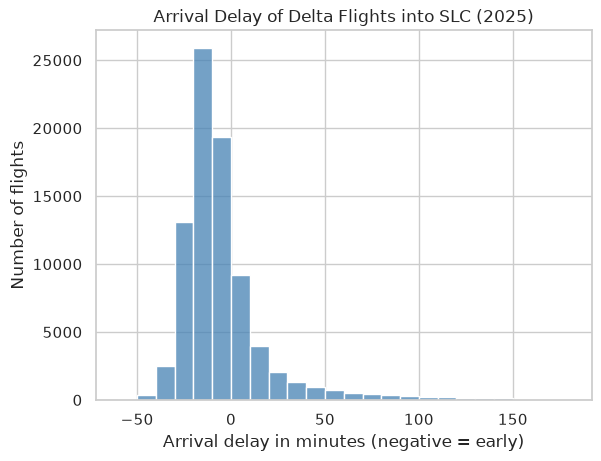

In [9]:
sns.histplot(flights['ArrDelay'], bins=range(-60, 181, 10), color='steelblue')
plt.title('Arrival Delay of Delta Flights into SLC (2025)')
plt.xlabel('Arrival delay in minutes (negative = early)')
plt.ylabel('Number of flights')
plt.show()

Most flights land a little early or right on time, and there is a long tail of late flights on the right side. We cut the chart off at 180 minutes so the shape is easier to see.

In [10]:
print(weather.isnull().sum())
weather.describe()

STATION    0
DATE       0
AWND       4
PRCP       0
SNOW       0
TMAX       2
TMIN       2
WSF2       3
dtype: int64


,AWND,PRCP,SNOW,TMAX,TMIN,WSF2
count,359.000000,363.000000,363.000000,361.000000,361.000000,360.000000
mean,8.201811,0.039091,0.044077,68.235457,47.426593,19.526111
std,3.704573,0.165053,0.286601,19.697785,15.968746,6.988493
min,2.910000,0.000000,0.000000,26.000000,15.000000,8.100000
25%,5.820000,0.000000,0.000000,53.000000,33.000000,14.100000
50%,7.160000,0.000000,0.000000,67.000000,45.000000,17.900000
75%,9.840000,0.000000,0.000000,87.000000,62.000000,23.900000
max,22.820000,2.470000,3.300000,104.000000,79.000000,40.900000


The weather file is missing a few wind and temperature values. Most days have no rain or snow, which is why the median for PRCP and SNOW is 0.

Issues we found that need to be fixed:

1. Cancelled and diverted flights have no arrival delay.
2. Column names are in mixed case and the weather names are hard to read.
3. FlightDate is text, not a date.
4. The weather file has 2 missing days and a few missing values.
5. There are some very long delays (outliers).

## 5. Data Cleaning and Preprocessing

### 5.1 Clean up the column names

We made the flight column names lowercase and gave the weather columns names that are easier to read.

In [11]:
flights.columns = flights.columns.str.lower()
weather.columns = ['station', 'flightdate', 'avg_wind', 'precip', 'snow', 'temp_max', 'temp_min', 'max_wind']

print(flights.columns.tolist())

['flightdate', 'month', 'dayofmonth', 'dayofweek', 'operating_airline', 'origin', 'origincityname', 'dest', 'crsdeptime', 'crsarrtime', 'depdelay', 'arrdelay', 'arrdel15', 'cancelled', 'diverted', 'crselapsedtime', 'distance', 'carrierdelay', 'weatherdelay', 'nasdelay', 'securitydelay', 'lateaircraftdelay']


### 5.2 Remove cancelled and diverted flights

Our question is about flights that arrive late, so flights that never arrived at SLC don't fit. We removed them, and then checked that no arrival delays are missing anymore.

In [12]:
flights = flights[(flights['cancelled'] == 0) & (flights['diverted'] == 0)]

print(flights.shape)
print("Missing arrival delays:", flights['arrdelay'].isnull().sum())

(82928, 22)
Missing arrival delays: 0


### 5.3 Check for outliers

In [13]:
print("Flights more than 5 hours late:", (flights['arrdelay'] > 300).sum())
print("Longest delay in minutes:", flights['arrdelay'].max())
print("Shortest and longest distance:", flights['distance'].min(), flights['distance'].max())

Flights more than 5 hours late: 358
Longest delay in minutes: 1819.0
Shortest and longest distance: 149.0 2994.0


358 flights were more than 5 hours late. We decided to keep them. They look like real flights, not typos, and our target is just late or not late, so a 30 hour delay counts the same as a 20 minute one. The distances also look normal (149 to 2,994 miles).

### 5.4 Fix the date columns

Both files need the date in the same format so we can join them.

In [14]:
flights['flightdate'] = pd.to_datetime(flights['flightdate'])
weather['flightdate'] = pd.to_datetime(weather['flightdate'])

### 5.5 Merge the flights with the weather

Every flight gets the SLC weather for the day it flew.

In [15]:
weather = weather.drop(columns=['station'])
df = pd.merge(flights, weather, on='flightdate', how='left')

print(df.shape)
print(df[['avg_wind', 'precip', 'snow', 'temp_max', 'temp_min', 'max_wind']].isnull().sum())

(82928, 28)
avg_wind    1327
precip       411
snow         411
temp_max     872
temp_min     872
max_wind    1100
dtype: int64


Some flights have no weather because of the missing days and values in the NOAA file. It is about 1,300 flights out of almost 83,000 (under 2%), so we dropped those rows instead of guessing what the weather was.

In [16]:
df = df.dropna(subset=['avg_wind', 'precip', 'snow', 'temp_max', 'temp_min', 'max_wind'])
print(df.shape)

(81601, 28)


### 5.6 Feature engineering

We made a few new columns:

- `late`: our target. 1 if the flight arrived 15 or more minutes late.
- `dep_hour` and `arr_hour`: the hour from the scheduled times (1435 becomes 14).
- `snow_day`: 1 if it snowed at SLC that day. We only use this one for a chart later.

In [17]:
df['late'] = df['arrdel15'].astype(int)
df['dep_hour'] = df['crsdeptime'] // 100
df['arr_hour'] = df['crsarrtime'] // 100
df['snow_day'] = (df['snow'] > 0).astype(int)

df[['crsdeptime', 'dep_hour', 'crsarrtime', 'arr_hour', 'snow', 'snow_day', 'arrdelay', 'late']].head()

,crsdeptime,dep_hour,crsarrtime,arr_hour,snow,snow_day,arrdelay,late
0,505,5,806,8,0.0,0,-32.0,0
1,510,5,810,8,0.0,0,-1.0,0
2,520,5,652,6,0.0,0,-26.0,0
3,525,5,729,7,0.0,0,-4.0,0
4,530,5,729,7,0.0,0,-5.0,0


We also grouped the arrival hour into four parts of the day with `pd.cut()`, which makes it easier to chart. Overnight is midnight to 5:59 am, Morning is 6 to 11:59 am, Afternoon is noon to 4:59 pm, and Evening is 5 pm to midnight.

In [18]:
df['time_of_day'] = pd.cut(df['arr_hour'], bins=[-1, 5, 11, 16, 23],
                           labels=['Overnight', 'Morning', 'Afternoon', 'Evening'])

df['time_of_day'].value_counts()

time_of_day
Afternoon    28282
Morning      27287
Evening      25425
Overnight      607
Name: count, dtype: int64

### 5.7 Encode the categorical variable

`operating_airline` is text (DL or OO), so we used one-hot encoding to turn it into a number column. We renamed it `regional_flight`, which is True when SkyWest flew the flight for Delta.

In [19]:
print(df['operating_airline'].value_counts())

df = pd.get_dummies(df, columns=['operating_airline'], drop_first=True)
df = df.rename(columns={'operating_airline_OO': 'regional_flight'})

print("Number of origin airports:", df['origin'].nunique())

operating_airline
DL    53327
OO    28274
Name: count, dtype: int64
Number of origin airports: 92


We did not encode `origin` because there are 92 airports, and that would add about 90 more columns. Distance and flight length already tell the model a lot about where the flight came from.

### 5.8 Scaling

We did not scale the data. Decision trees and random forests split on one column at a time, so the size of the numbers doesn't matter to them. We also did not scale for Naive Bayes, to keep things simple.

### 5.9 Look at the cleaned data

Share of flights that arrived late: 0.12330731241038713


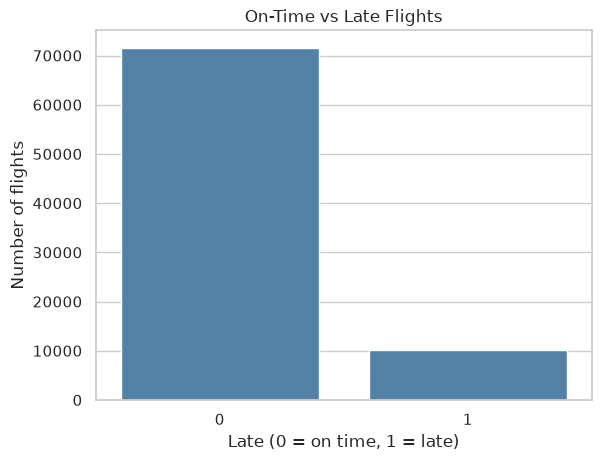

In [20]:
print("Share of flights that arrived late:", df['late'].mean())

sns.countplot(data=df, x='late', color='steelblue')
plt.title('On-Time vs Late Flights')
plt.xlabel('Late (0 = on time, 1 = late)')
plt.ylabel('Number of flights')
plt.show()

About 12.3% of Delta flights into SLC were late in 2025. That means the data is unbalanced, with about 7 on-time flights for every late one. That makes accuracy a bad way to judge the models, which we get to in section 6.

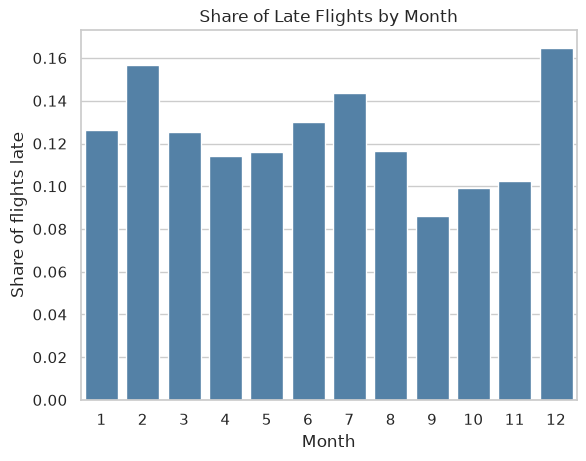

month
1     0.127
2     0.157
3     0.126
4     0.114
5     0.116
6     0.130
7     0.144
8     0.116
9     0.086
10    0.099
11    0.103
12    0.165
Name: late, dtype: float64


In [21]:
sns.barplot(data=df, x='month', y='late', color='steelblue', errorbar=None)
plt.title('Share of Late Flights by Month')
plt.xlabel('Month')
plt.ylabel('Share of flights late')
plt.show()

print(df.groupby('month')['late'].mean().round(3))

December (16.5%) and February (15.7%) were the worst months, and July was also high (14.4%). September was the best at 8.6%. So the winter months and July look like the hardest times of year.

In [22]:
df.groupby('regional_flight')['late'].mean()

regional_flight
False    0.153750
True     0.065891
Name: late, dtype: float64

Flights flown by SkyWest were late less often (6.6%) than flights flown by Delta itself (15.4%).

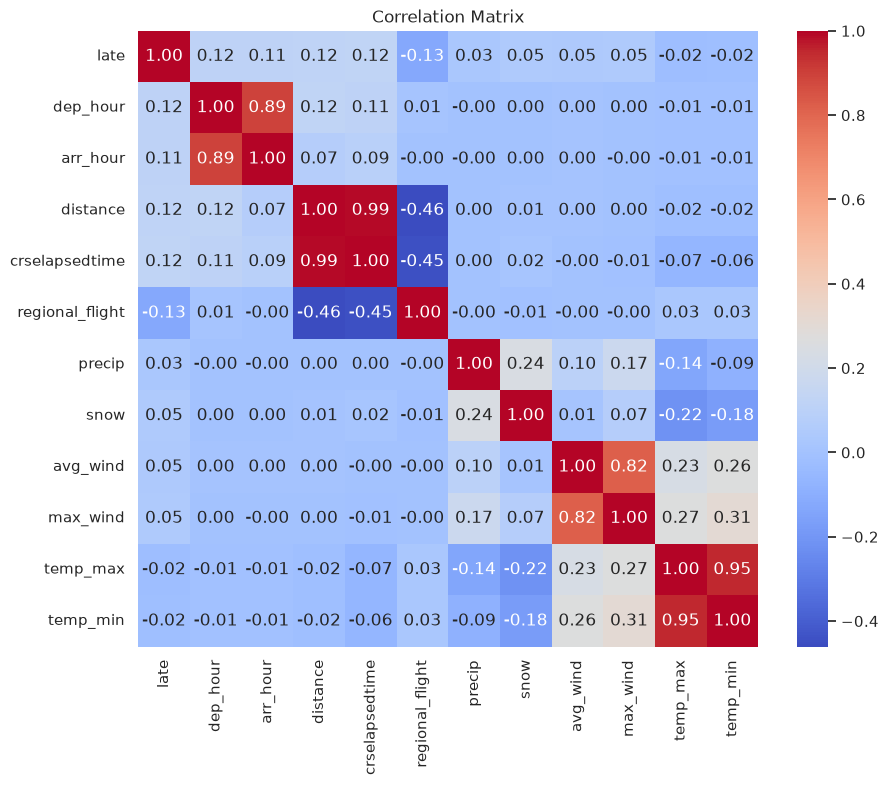

In [23]:
corr_cols = ['late', 'dep_hour', 'arr_hour', 'distance', 'crselapsedtime', 'regional_flight',
             'precip', 'snow', 'avg_wind', 'max_wind', 'temp_max', 'temp_min']

plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

Nothing has a strong correlation with `late`. The biggest ones are only around 0.12 (departure hour, distance, and flight length), and `regional_flight` is -0.13. So we already expected this to be a hard thing to predict. Distance and flight length are almost the same thing (0.99). We kept both because tree models are not hurt by two columns that are alike.

## 6. Modeling Approach

### What we are predicting

This is a classification problem. The target is `late` (1 or 0).

### Features

We only used things Delta knows before the flight: the schedule, the route, who is flying it, and the weather (which Delta would get from a forecast). We left out `depdelay` on purpose. A flight that leaves late usually arrives late, but you only know the departure delay after the plane has left, which is too late to change the schedule or plan gates.

One thing to know is that we used the actual weather recorded for each day. Delta would only have a forecast, so in real life the weather columns would be a little less accurate.

### Models

All three were covered in class.

| Model | Why we picked it |
|---|---|
| Decision Tree | Easy to explain to managers because you can see the rules it uses. |
| Random Forest | Combines a lot of trees, so it is usually more accurate and overfits less than one tree. |
| Naive Bayes | A very different kind of model that is fast and based on probabilities, so it is a good comparison. |

### Train/test split

We used 80% of the flights to train and 20% to test. We used `stratify=y` so both sets have the same share of late flights.

In [24]:
features = ['month', 'dayofweek', 'dep_hour', 'arr_hour', 'distance', 'crselapsedtime', 'regional_flight',
            'precip', 'snow', 'avg_wind', 'max_wind', 'temp_max', 'temp_min']

X = df[features]
y = df['late']

Then we split the data into training and test sets.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(65280, 13) (16321, 13)


### Baseline

Before building a model, we checked what happens if you just guess that every flight is on time.

In [26]:
baseline = 1 - y_test.mean()
print("Baseline accuracy (guess every flight is on time):", baseline)

Baseline accuracy (guess every flight is on time): 0.8767232399975492


Guessing "on time" every time is right 87.7% of the time, but it finds zero late flights, so it is useless to Delta. Because of that, accuracy is not a good way to judge these models. We used these instead:

- Recall: out of all the flights that were really late, how many did the model catch?
- Precision: out of the flights the model said would be late, how many really were?
- F1: one score that balances the two. This is the main number we used to pick the best model.

## 7. Model Implementation

### 7.1 Model 1: Decision Tree

In [27]:
# Start with a simple tree (max depth of 4)
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

print("Accuracy:", accuracy_score(y_test, tree_pred))
print("Recall:", recall_score(y_test, tree_pred))
print(confusion_matrix(y_test, tree_pred))

Accuracy: 0.8767232399975492
Recall: 0.0
[[14309     0]
 [ 2012     0]]


The first tree has the exact same accuracy as the baseline, and the confusion matrix shows why. It predicted "on time" for every single flight. Since only 12% of flights are late, the tree gets the best accuracy by never predicting late.

**Tuning:** To fix this we added `class_weight='balanced'`. That setting tells the tree to treat the late flights as more important, since there are so few of them. Then we tried a few values for `max_depth` to see which works best.

In [28]:
# Try different tree depths with balanced class weights
for depth in [4, 6, 8, 10, 12]:
    model = DecisionTreeClassifier(max_depth=depth, class_weight='balanced', random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print("Depth", depth, "| precision:", round(precision_score(y_test, pred), 3),
          "| recall:", round(recall_score(y_test, pred), 3), "| F1:", round(f1_score(y_test, pred), 3))

Depth 4 | precision: 0.176 | recall: 0.726 | F1: 0.284


Depth 6 | precision: 0.193 | recall: 0.652 | F1: 0.298


Depth 8 | precision: 0.192 | recall: 0.645 | F1: 0.296


Depth 10 | precision: 0.192 | recall: 0.654 | F1: 0.296


Depth 12 | precision: 0.189 | recall: 0.619 | F1: 0.29


Now the tree finds late flights. A depth of 6 had the best F1 (0.298). Deeper trees did not do any better, so we kept it at 6.

In [29]:
# Final decision tree
tree = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

print("Accuracy:", accuracy_score(y_test, tree_pred))
print("Precision:", precision_score(y_test, tree_pred))
print("Recall:", recall_score(y_test, tree_pred))
print("F1:", f1_score(y_test, tree_pred))
print("Share of flights flagged:", tree_pred.mean())

Accuracy: 0.621530543471601
Precision: 0.19325379290027986
Recall: 0.6520874751491054
F1: 0.2981479377343484
Share of flights flagged: 0.4159671588750689


**Final settings:** `max_depth=6`, `class_weight='balanced'`. The tree catches about 65% of late flights. Accuracy dropped to 62% because it now flags a lot of flights that end up on time.

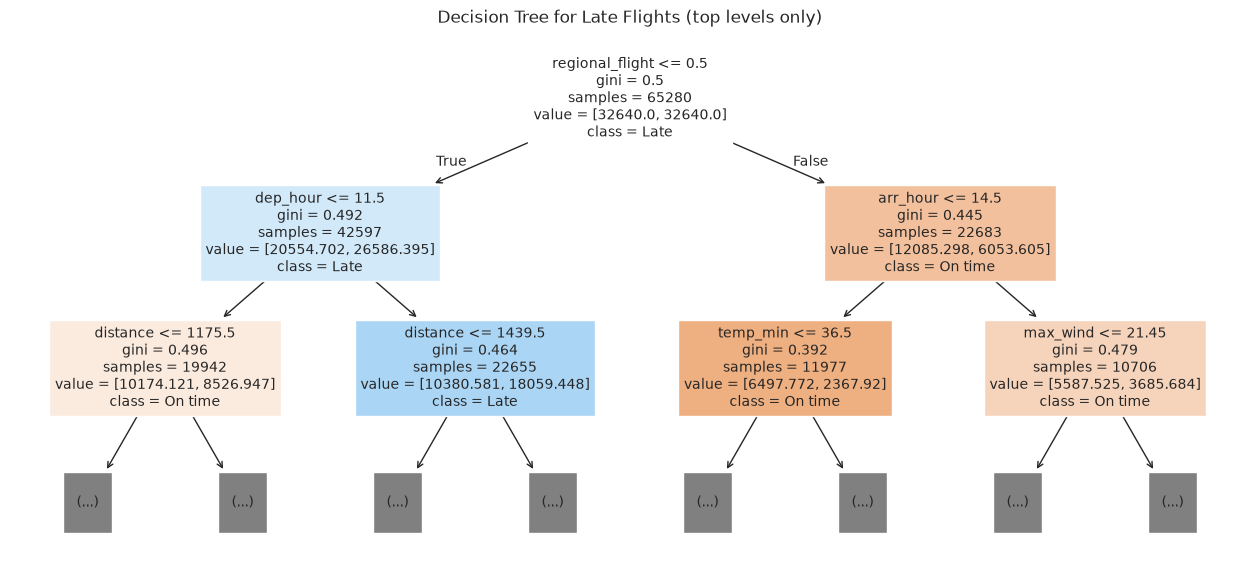

In [30]:
# Show only the top 2 levels so the tree is readable
plt.figure(figsize=(16, 7))
plot_tree(tree, max_depth=2, feature_names=X.columns, class_names=['On time', 'Late'], filled=True, fontsize=10)
plt.title('Decision Tree for Late Flights (top levels only)')
plt.show()

The first thing the tree splits on is whether it is a regional flight. After that it looks at the departure and arrival hour, then distance and weather. The numbers in the `value` lines look odd because of the balanced weights.

### 7.2 Model 2: Random Forest

We used the same `class_weight='balanced'` setting and 100 trees, and tried different depths.

In [31]:
# Try different depths for the random forest
for depth in [6, 10, 14, 18]:
    model = RandomForestClassifier(n_estimators=100, max_depth=depth, class_weight='balanced', random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print("Depth", depth, "| precision:", round(precision_score(y_test, pred), 3),
          "| recall:", round(recall_score(y_test, pred), 3), "| F1:", round(f1_score(y_test, pred), 3))

Depth 6 | precision: 0.193 | recall: 0.677 | F1: 0.3


Depth 10 | precision: 0.215 | recall: 0.636 | F1: 0.321


Depth 14 | precision: 0.241 | recall: 0.506 | F1: 0.327


Depth 18 | precision: 0.27 | recall: 0.376 | F1: 0.314


As the forest gets deeper, precision goes up and recall goes down. Depth 14 had the best F1 (0.327), so we used that.

In [32]:
# Final random forest
rf = RandomForestClassifier(n_estimators=100, max_depth=14, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1:", f1_score(y_test, rf_pred))

Accuracy: 0.7428466392990626
Precision: 0.24129765569500355
Recall: 0.5064612326043738
F1: 0.3268644747393745


**Final settings:** `n_estimators=100`, `max_depth=14`, `class_weight='balanced'`.

In [33]:
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
rf_importance

crselapsedtime     0.155090
distance           0.143711
dep_hour           0.094774
arr_hour           0.094072
temp_max           0.078869
temp_min           0.077660
avg_wind           0.075191
regional_flight    0.071253
max_wind           0.067275
month              0.050210
dayofweek          0.046108
precip             0.034353
snow               0.011435
dtype: float64

Flight length and distance are the most important, then the scheduled hours and the temperature. Snow is at the bottom, which surprised us. We think it's because it only snowed on a small number of days, so it can't help with most flights.

### 7.3 Model 3: Naive Bayes

In class we used BernoulliNB and MultinomialNB, which are made for yes/no and count columns. Most of our columns are measurements like distance and temperature, so we used `GaussianNB`, which is the same model for that kind of data. It doesn't have settings like depth to tune, and it has no `class_weight` setting, so we tried feature selection instead.

In [34]:
# Naive Bayes with all of the features
nb = GaussianNB()
nb.fit(X_train, y_train)
nb_pred = nb.predict(X_test)

print("Precision:", precision_score(y_test, nb_pred))
print("Recall:", recall_score(y_test, nb_pred))
print("F1:", f1_score(y_test, nb_pred))

Precision: 0.22123893805309736
Recall: 0.16153081510934394
F1: 0.18672795173800633


**Feature selection:** We tried Naive Bayes again with only the 6 most important features from the random forest.

In [35]:
# Naive Bayes with only the top 6 features from the random forest
top_features = rf_importance.index[:6]

nb_top = GaussianNB()
nb_top.fit(X_train[top_features], y_train)
nb_top_pred = nb_top.predict(X_test[top_features])

print("Precision:", precision_score(y_test, nb_top_pred))
print("Recall:", recall_score(y_test, nb_top_pred))
print("F1:", f1_score(y_test, nb_top_pred))

Precision: 0.23518687329079307
Recall: 0.12823061630218688
F1: 0.1659697651978128


Using fewer features made it a little worse (F1 went from 0.187 to 0.166), so we kept the version with all of the features.

**Final settings:** `GaussianNB` with default settings and all 13 features.

## 8. Model Evaluation

### 8.1 Compare the three models

In [36]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest', 'Naive Bayes'],
    'Accuracy': [accuracy_score(y_test, tree_pred), accuracy_score(y_test, rf_pred), accuracy_score(y_test, nb_pred)],
    'Precision': [precision_score(y_test, tree_pred), precision_score(y_test, rf_pred), precision_score(y_test, nb_pred)],
    'Recall': [recall_score(y_test, tree_pred), recall_score(y_test, rf_pred), recall_score(y_test, nb_pred)],
    'F1': [f1_score(y_test, tree_pred), f1_score(y_test, rf_pred), f1_score(y_test, nb_pred)]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.622,0.193,0.652,0.298
1,Random Forest,0.743,0.241,0.506,0.327
2,Naive Bayes,0.827,0.221,0.162,0.187


- Naive Bayes has the highest accuracy (82.7%), but only because it rarely predicts late. It catches just 16% of late flights. Part of that is because it could not be balanced the way the other two were.
- The decision tree catches the most late flights (65%), but it has the lowest precision, so it flags a lot of flights that are fine.
- The random forest has the best F1 (0.327) and the best precision (0.241). It catches about half of the late flights.

All three have lower accuracy than the 87.7% baseline. That is expected, because the baseline gets its accuracy by never flagging a late flight.

### 8.2 A closer look at the random forest

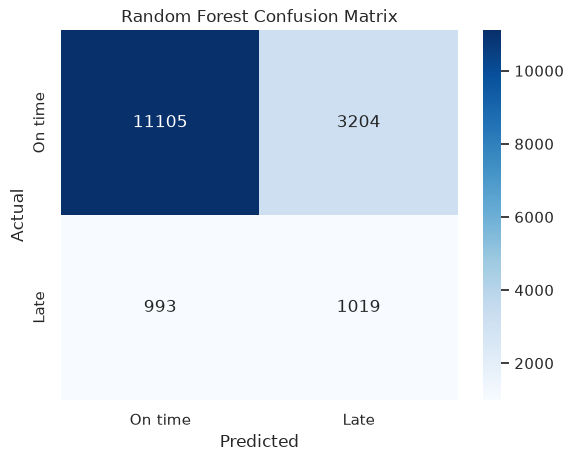

In [37]:
cm = confusion_matrix(y_test, rf_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['On time', 'Late'], yticklabels=['On time', 'Late'])
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Out of 2,012 late flights in the test set, the random forest caught 1,019 and missed 993. It also flagged 3,204 flights that ended up on time.

In [38]:
# Compare flights the model flagged with flights it did not flag
check = pd.DataFrame({'flagged': rf_pred, 'late': y_test})

print("Share of flights flagged:", check['flagged'].mean())
print(check.groupby('flagged')['late'].mean())

Share of flights flagged: 0.25874640034311625
flagged
0    0.082080
1    0.241298
Name: late, dtype: float64


### 8.3 What this means for the business

The random forest flags about 26% of flights. Of the flights it flags, 24% end up late. Of the flights it does not flag, only 8% are late. So a flagged flight is about 3 times more likely to be late.

The model is not good enough to say for sure that one specific flight will be late. Most flagged flights still arrive on time. But it works as a way to sort flights by risk. If Delta focused on the quarter of flights that are flagged, it would cover about half of all the late arrivals.

The scores are low because our features are only the schedule and the daily weather. The delay cause data (Chart 3 below) shows that most delay time comes from airline problems and late incoming planes, and you can't see those ahead of time in this data.

### 8.4 Limits of our testing

Our scores are probably a little higher than Delta would get in real life, for three reasons. We picked the depth settings using the test set. We split the flights randomly, so flights from the same day (with the same weather) are in both the training and test sets. And we used the actual weather, not a forecast.

## 9. Final Descriptive Charts

These are the charts we use in our presentation.

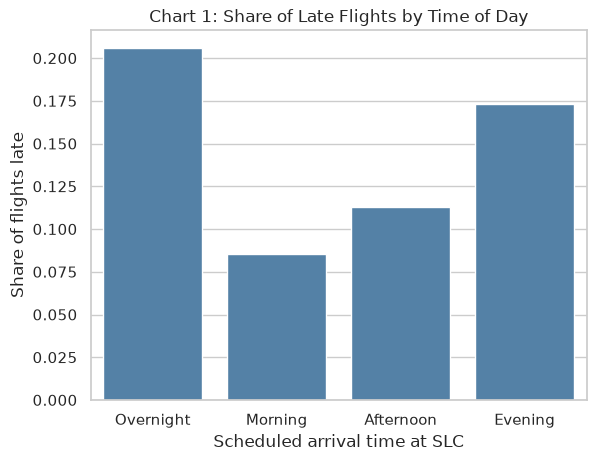

time_of_day
Overnight    0.206
Morning      0.086
Afternoon    0.113
Evening      0.173
Name: late, dtype: float64


In [39]:
sns.barplot(data=df, x='time_of_day', y='late', color='steelblue', errorbar=None)
plt.title('Chart 1: Share of Late Flights by Time of Day')
plt.xlabel('Scheduled arrival time at SLC')
plt.ylabel('Share of flights late')
plt.show()

print(df.groupby('time_of_day', observed=True)['late'].mean().round(3))

Morning arrivals are late the least (8.6%). Evening arrivals are late about twice as often (17.3%), so it looks like delays build up during the day. Overnight arrivals are the highest at 20.6%, but there are only about 600 of those flights all year.

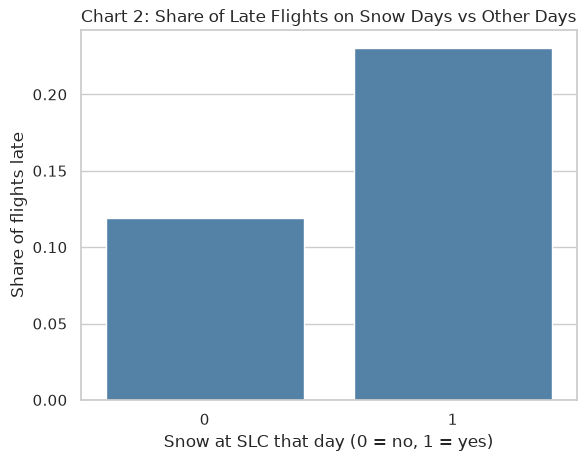

snow_day
0    0.119
1    0.230
Name: late, dtype: float64


In [40]:
sns.barplot(data=df, x='snow_day', y='late', color='steelblue', errorbar=None)
plt.title('Chart 2: Share of Late Flights on Snow Days vs Other Days')
plt.xlabel('Snow at SLC that day (0 = no, 1 = yes)')
plt.ylabel('Share of flights late')
plt.show()

print(df.groupby('snow_day')['late'].mean().round(3))

On days with snow at SLC, 23% of flights were late, compared to 11.9% on other days.

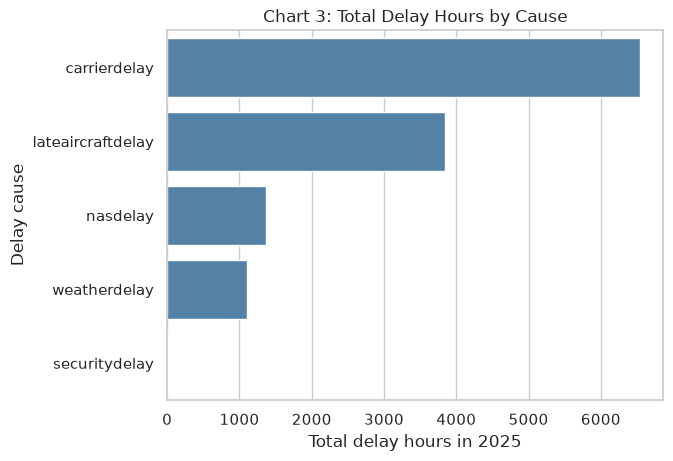

In [41]:
cause_cols = ['carrierdelay', 'lateaircraftdelay', 'nasdelay', 'weatherdelay', 'securitydelay']
cause_hours = (df[cause_cols].sum() / 60).sort_values(ascending=False)

sns.barplot(x=cause_hours.values, y=cause_hours.index, color='steelblue')
plt.title('Chart 3: Total Delay Hours by Cause')
plt.xlabel('Total delay hours in 2025')
plt.ylabel('Delay cause')
plt.show()

Carrier delays (things like maintenance and crew) and late incoming aircraft cause most of the delay time. Weather is a much smaller part than we expected. Snow days are still bad days, but there were not many of them, so they don't add up to much of the total.

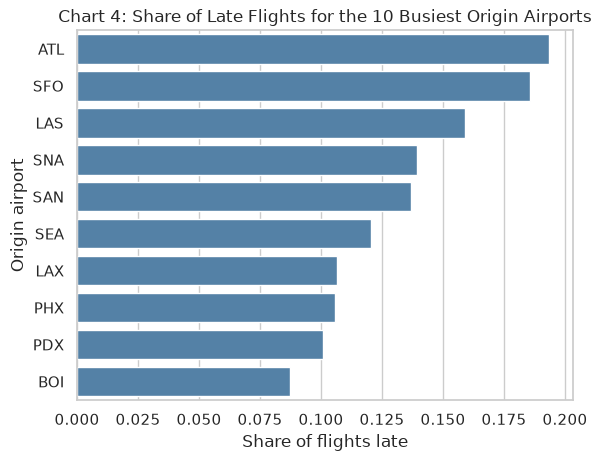

origin
ATL    0.194
SFO    0.186
LAS    0.159
SNA    0.140
SAN    0.137
SEA    0.120
LAX    0.106
PHX    0.106
PDX    0.101
BOI    0.087
Name: late, dtype: float64


In [42]:
top_origins = df['origin'].value_counts().index[:10]
origin_late = df[df['origin'].isin(top_origins)].groupby('origin')['late'].mean().sort_values(ascending=False)

sns.barplot(x=origin_late.values, y=origin_late.index, color='steelblue')
plt.title('Chart 4: Share of Late Flights for the 10 Busiest Origin Airports')
plt.xlabel('Share of flights late')
plt.ylabel('Origin airport')
plt.show()

print(origin_late.round(3))

Among the 10 busiest routes, flights from Atlanta (19.4%) and San Francisco (18.6%) are late the most. Boise is the lowest at 8.7%.

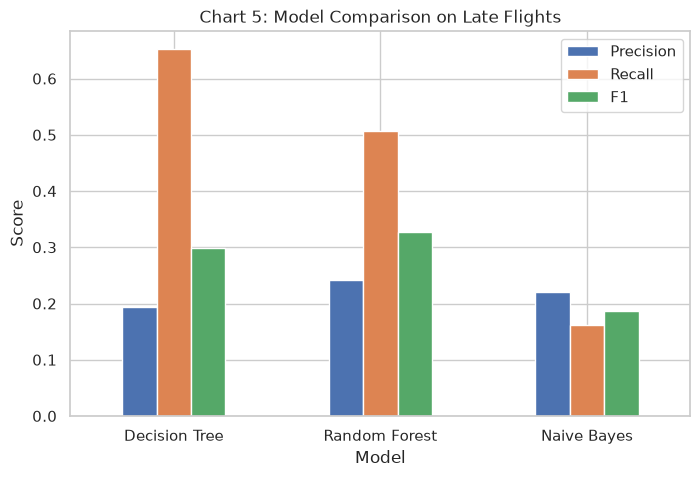

In [43]:
results.set_index('Model')[['Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(8, 5))
plt.title('Chart 5: Model Comparison on Late Flights')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.show()

The random forest has the best balance of precision and recall.

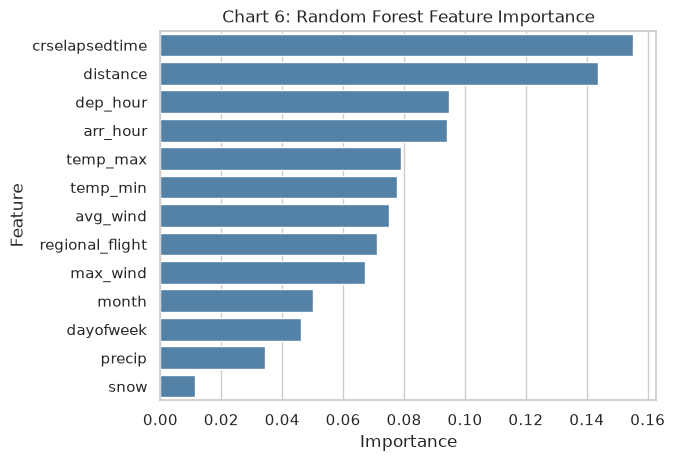

In [44]:
sns.barplot(x=rf_importance.values, y=rf_importance.index, color='steelblue')
plt.title('Chart 6: Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

The route and the time of day matter more than any single weather measure.

## 10. Conclusions and Recommendations

### What we did

1. Picked a business problem: late arrivals at Delta's Salt Lake City hub.
2. Got every Delta flight into SLC for 2025 from BTS and daily weather from NOAA.
3. Explored the data and found missing values, cancelled flights, and outliers.
4. Cleaned the data, merged the two files, and made new features.
5. Built and tuned three models: a decision tree, a random forest, and Naive Bayes.
6. Compared them using precision, recall, and F1.

### Best model

We recommend the random forest. It had the best F1 score (0.327) and the best precision. The decision tree catches more late flights, but it flags over 40% of all flights to do it (compared to 26% for the random forest), which is too many to act on. Naive Bayes misses most of the late flights. The decision tree is still useful for explaining the patterns to managers because you can see its rules.

### Recommendations for Delta

1. Delta should use the model to rank flights by risk. Flagged flights are about 3 times more likely to be late, so they are the ones to plan around first.
2. Delta should add extra time to the schedule for evening arrivals and the worst routes. Evening flights are late about twice as often as morning flights, and Atlanta and San Francisco are the worst of the busy routes.
3. Delta should plan for extra gates and crew on snow days and in December and February. The late rate was almost double on the days it snowed.
4. Delta should work on carrier and late aircraft delays. Those two cause most of the delay time, and they are more in Delta's control than the weather is.

### How Delta could use the model

Delta could run the model each morning with that day's schedule and the weather forecast. It would give a list of the flights most likely to arrive late, and the hub team could plan gates, crews, and rebooking around that list.

### Next steps

- Add the status of the incoming plane, since late aircraft is one of the biggest causes. This would probably help the model the most.
- Add weather at the origin airport, not only at SLC.
- Use hourly weather instead of one number for the whole day.
- Build a second model that uses the departure delay once a flight has taken off. That one could be used to rebook passengers with tight connections before they land.
- Test on more than one year of data.